# Plasma Potential Calculation

## Recreating figure 1 from NASA paper

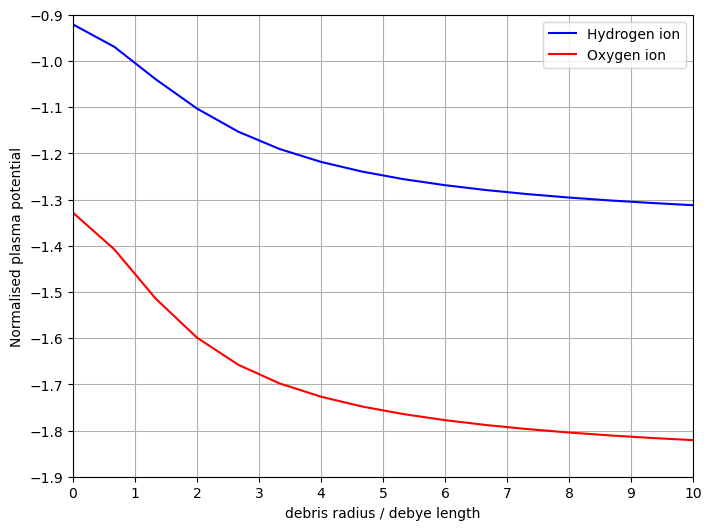

In [1]:
from scipy.optimize import brentq
import numpy as np
import matplotlib.pyplot as plt

def surface_potential_equation(x, mass_ratio, s, a):
    """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function """
    return np.exp(x) - np.sqrt(mass_ratio) * ((s/a)**2) * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))


#consants
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg
debye_length = 1 # Example value for debye radius

r = debye_length # Distance from the debris surface the potnetial is felt too, which for plasma is the debye length, this is used to normalise the plasma potential

a_array = np.linspace( 1e-3, 10, 16) # Array of debris radii from 0.00001 to 10 in 16 steps

phi_ox= np.zeros(len(a_array))
phi_h = np.zeros(len(a_array))

# Calculate the normalised plasma potential for each debris radius
for i, a in enumerate(a_array):
    mass_ratio = __me__ / __mo__
    s = a + debye_length
    x_solution = brentq(surface_potential_equation, -20, 0, args=(mass_ratio, s, a))
    phi_ox[i] = x_solution * np.exp(-r/ debye_length)  # normalised plasma potential

for i, a in enumerate(a_array):
    mass_ratio = __me__ / __mh__
    s = a + debye_length
    x_solution = brentq(surface_potential_equation, -20, 0, args=(mass_ratio, s, a))
    phi_h[i] = x_solution * np.exp(-r/ debye_length)  # normalised plasma potential


# PLOTTING
plt.figure(figsize=(8, 6))
plt.grid()
plt.plot(a_array / debye_length, phi_h, label="Hydrogen ion", color="blue")
plt.plot(a_array/ debye_length, phi_ox, label="Oxygen ion", color="red")
plt.xlabel("debris radius / debye length")
plt.ylabel("Normalised plasma potential")
plt.xticks(np.arange(0, 11, 1))
plt.yticks(np.arange(-2, 1, 0.1))
plt.xlim(0, 10)
plt.ylim( -1.9,-0.9)
plt.legend()
plt.show()

### Functionisng the Normalised Plasma Potential Calculation & Validating against NASA paper values (Table 6)

In [2]:
from scipy.optimize import brentq
import numpy as np

def normalised_plasma_potential(a, debye_length, mass_ratio, potential_radius = None):
    """Calculates the normalised plasma potential for a given debris radius, debye length, and mass ratio."""
    def eqn_surface_potential(x, mass_ratio, s, a):
        """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function, eφ/kT"""
        return np.exp(x) - np.sqrt(mass_ratio) * (s/a)**2  * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))

    # If potential_radius is not provided, it defaults to the debye_length.
    if potential_radius is None:
        potential_radius = debye_length

    s = a + debye_length

    x_sol = brentq(eqn_surface_potential, -10, 0, args=(mass_ratio, s, a))
    phi_np = x_sol * np.exp(-potential_radius/debye_length)  # normalised plasma potential

    return phi_np

# ========= Validation against NASA paper values (Table 6) =========
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg

mass_ratio_o = __me__ / __mo__
mass_ratio_h = __me__ / __mh__

# values extracted from NASA paper Table 6 f

debris_diameters= [10e-2, 5e-2, 1e-2, 5e-3, 1e-3] # Debris diameters in meters
debye_lengths = [.83e-2, 1.38e-2, 4.36e-2, 23504e-2] # Debye lengths for Low LEO, Low LEO I, Low LEO II, and GEO respectively in meters

lowleo_phi_values = [-1.77, -1.68, -1.40, -1.35, -1.33]
lowleoi_phi_values = [-1.20, -1.08, -0.94, -0.93, -0.92]
lowleoii_phi_values = [-1.02, -0.96, -0.92, -0.92, -0.92]

debris_radii = [d/2 for d in debris_diameters] # Debris radii in meters

# Low LEO
print("=Normalised plasma potential calculations for Low LEO region (Oxygen)=:")
for a in debris_radii:
    phi_lowleo = normalised_plasma_potential(a, debye_lengths[0], mass_ratio_o)
    uncertainty = abs(phi_lowleo - lowleo_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleo:.3f}, uncertainty: {uncertainty:.3f}")

# Low LEO I
print("\n=Normalised plasma potential calculations for Low LEO I region (Hydrogen)=:")
for a in debris_radii:
    phi_lowleoi = normalised_plasma_potential(a, debye_lengths[1], mass_ratio_h)
    uncertainty = abs(phi_lowleoi - lowleoi_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleoi:.3f}, uncertainty: {uncertainty:.3f}")

# Low LEO II
print("\n=Normalised plasma potential calculations for Low LEO II region (Hydrogen)=:")
for a in debris_radii:
    phi_lowleoii = normalised_plasma_potential(a, debye_lengths[2], mass_ratio_h)
    uncertainty = abs(phi_lowleoii - lowleoii_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleoii:.3f}, uncertainty: {uncertainty:.3f}")

=Normalised plasma potential calculations for Low LEO region (Oxygen)=:
Debris radius: 5.0e-02 m, Normalised plasma potential: -1.778, uncertainty: 0.008
Debris radius: 2.5e-02 m, Normalised plasma potential: -1.680, uncertainty: 0.000
Debris radius: 5.0e-03 m, Normalised plasma potential: -1.398, uncertainty: 0.002
Debris radius: 2.5e-03 m, Normalised plasma potential: -1.353, uncertainty: 0.003
Debris radius: 5.0e-04 m, Normalised plasma potential: -1.330, uncertainty: 0.000

=Normalised plasma potential calculations for Low LEO I region (Hydrogen)=:
Debris radius: 5.0e-02 m, Normalised plasma potential: -1.204, uncertainty: 0.004
Debris radius: 2.5e-02 m, Normalised plasma potential: -1.086, uncertainty: 0.006
Debris radius: 5.0e-03 m, Normalised plasma potential: -0.941, uncertainty: 0.001
Debris radius: 2.5e-03 m, Normalised plasma potential: -0.927, uncertainty: 0.003
Debris radius: 5.0e-04 m, Normalised plasma potential: -0.921, uncertainty: 0.001

=Normalised plasma potential c

calculating forcing term in low leo


Plotting.


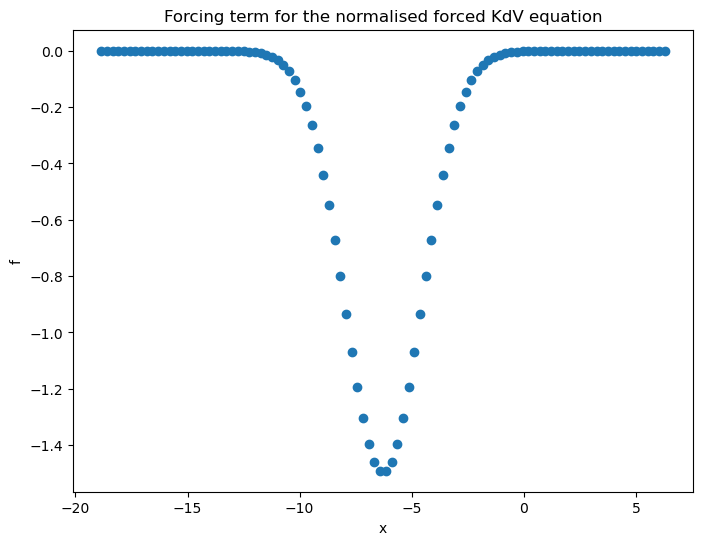

In [3]:
from scipy.optimize import brentq
import numpy as np
import matplotlib.pyplot as plt

def forcing_term(np_potential, xi, tau, vd, G):
    return np_potential * np.exp(-1 * ((e - (vd * tau))/ G)**2)


a = 0.01 # Debris radius in m
L =  2*np.pi# size of the domain
vd = 0
N = 100

tau = np.linspace(0, L, N)
xi = np.linspace(-3* L, L, N)

e = ( np.pi / L ) * (xi + L)

debye_length = .83e-2
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg
mass_ratio_o = __me__ / __mo__


G = a / debye_length # Normalised forcing width
np_potential = normalised_plasma_potential(a, debye_length, mass_ratio_o)


print("Plotting.")

# 3D surface plot

f = forcing_term(np_potential, xi, 1, vd, G)

plt.figure(figsize=(8, 6))
plt.scatter(xi, f)
plt.xlabel('x')
plt.ylabel('f')
plt.title('Forcing term for the normalised forced KdV equation')
plt.show()

# Plasma solution simulation



## Functions

In [12]:
def initialise_ionosphere_region(df, region):
    """ takes a dataframe of ionospheric properties and pulls the associated properties for a given region. making the necessary calculations required to run simulation CURRENTLY NOT ABLE TO HANDLE GEO"""

    # Pulls property name and values into a list and numpy array respectively
    value = df_ionosphere[region].to_numpy()
    properties =  df_ionosphere["Properties"].to_list()

    # Creates a dictionary of the properties and values for the given region
    plasma_properties = dict(zip(properties, value))
    return plasma_properties

def normalised_plasma_potential(a, debye_length, mass_ratio, potential_radius = None):
    """Calculates the normalised plasma potential for a given debris radius, debye length, and mass ratio."""
    def eqn_surface_potential(x, mass_ratio, s, a):
        """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function, eφ/kT"""
        return np.exp(x) - np.sqrt(mass_ratio) * (s/a)**2  * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))

    # If potential_radius is not provided, it defaults to the debye_length.
    if potential_radius is None:
        potential_radius = debye_length

    s = a + debye_length

    x_sol = brentq(eqn_surface_potential, -10, 0, args=(mass_ratio, s, a))
    phi_np = x_sol * np.exp(-potential_radius/debye_length)  # normalised plasma potential

    return phi_np

def forcing_term(np_potential, xi, tau, vd, G):
    return np_potential * np.exp(-1 * ((xi - (vd * tau))/ G)**2)

def fkdv_exact_solution(a, x, K = 0.6124):
    return a / (np.cosh(K * x)**2)

def ck_solutions(last_sol, current_sol, alpha, beta, s, k, f, dt):
    """Use the Crank-Nicolson scheme to solve the normalised forced KdV equation on a periodic domain."""
    # pre-calculating coefficients
    _ck_beta = dt * beta * 1j * s**3 * k**3
    _ck_z = dt * 1j * s * k

    # computing the rfft of u & f halfs the length of array which then is multipled by 1024 leng coefficents arrays because of k
    _ck_beta_fft = _ck_beta[:len(k)//2+1]  # Keep only first 513 elements
    _ck_z_fft = _ck_z[:len(k)//2+1]

    # Fourier transform of the last solution, current solution, and forcing term
    fft_last = rfft(last_sol)
    fft_current_sqrd = rfft(current_sol**2)
    fft_f = rfft(f)

    return irfft( ((1 - _ck_beta_fft)**-1) * ( (1 + _ck_beta_fft) * fft_last - alpha * _ck_z_fft * (fft_current_sqrd) + _ck_z_fft * fft_f ) )

## Imports & variables

In [15]:
import numpy as np
from numpy.fft import rfft, irfft
import pandas as pd
from numpy import pi, cos, linspace, arange
from scipy.fftpack import diff as psdiff
import pandas as pd
import matplotlib.pyplot as plt
from IPython.core.pylabtools import figsize
from scipy.optimize import brentq

# Upload the Ionosphere properties from the Excel file
df_ionosphere= pd.read_excel(r'Ionosphere prop.xltx')
display(df_ionosphere)

# Pulls the properties for the Low LEO region into a dictionary
plasma_prop = initialise_ionosphere_region(df_ionosphere, "Low LEO")

# =============================== Inputs ================================

# Global constants
__kb__ = 1.380649e-23  #Boltzmann constant in J/K
__c__ = 299792458.0  # Speed of light in m/s
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg

# Physical parameters
a = 0.01 # debris in m
alpha = 1.0051
beta = 0.4925
vd = 1.20 # Debris velocity in km/s
np_potential = None # Normalised plasma potential, if None, it will be automatically calculated.

# Simulation parameters
N = 1024 # number of discretised points in the domain (power of 2 for FFT speed)
L = 300.0 # size of the domain
G = a / (plasma_prop["Debye Length"] * 1e-2) # Normalised forcing width
dtau = 0.002# TU
tau_inital = 0.0  # TU
tau_final = 60.0 # TU

# Normlaised units
TU = (plasma_prop["Debye Length"] * 1e-2) / (plasma_prop["Ion Acoustic Velocity"] * 1e3) # Time unit in seconds
vd_norm = vd / (plasma_prop["Ion Acoustic Velocity"] * 1e3) # Normalised debris velocity

# Determine the ion species and set the corresponding ion mass and mass ratio
if plasma_prop["Ion Species"] == "O":
    mi = __mo__
    mass_ratio = __me__ / __mo__
elif plasma_prop["Ion Species"] == "H":
    mi= __mh__
    mass_ratio = __me__ / __mh__
else:
    raise ValueError("Ion species not recognised. Please use 'O' for Oxygen or 'H' for Hydrogen.")

# if up
if np_potential is None:
    np_potential = normalised_plasma_potential(a, plasma_prop["Debye Length"], mass_ratio)

,Properties,Units,Low LEO,High LEO I,High LEO II,GEO
0,Altitude,km,700,1200,1400,35786
1,Latitude,deg,"0,50",0-55,0-55,0-90
2,Electron Density,cm^-3,200000,100000,10000,1
3,Electron Tempreture,eV,0.25,0.35,0.35,1000
4,Ion Species,NaN,O,H,H,OH
5,Ion Mass,proton mass,16,1,1,"16,1"
6,Debye Length,cm,0.83,1.38,4.36,23504
7,Debris Velocity Circular Orbit,km/s,7.51,7.26,7.16,3.08
8,Ion Acoustic Velocity,km/s,1.22,5.75,5.75,"77.43 , 309.73"


## Main

Time step: 1000, Time: 1.99 TU
Max value of solution: 0.5331, Min value of solution: -0.6601
Time step: 2000, Time: 3.99 TU
Max value of solution: 0.9048, Min value of solution: -0.8861
Time step: 3000, Time: 5.99 TU
Max value of solution: 1.2417, Min value of solution: -1.0145
Time step: 4000, Time: 7.99 TU
Max value of solution: 1.5681, Min value of solution: -1.0991
Time step: 5000, Time: 9.99 TU
Max value of solution: 1.8048, Min value of solution: -1.1536
Time step: 6000, Time: 11.99 TU
Max value of solution: 1.9616, Min value of solution: -1.1712
Time step: 7000, Time: 13.99 TU
Max value of solution: 2.0655, Min value of solution: -1.1635
Time step: 8000, Time: 15.99 TU
Max value of solution: 2.1364, Min value of solution: -1.1466
Time step: 9000, Time: 17.99 TU
Max value of solution: 2.1865, Min value of solution: -1.1278
Time step: 10000, Time: 19.99 TU
Max value of solution: 2.2223, Min value of solution: -1.1530
Time step: 11000, Time: 21.99 TU
Max value of solution: 2.2475, 

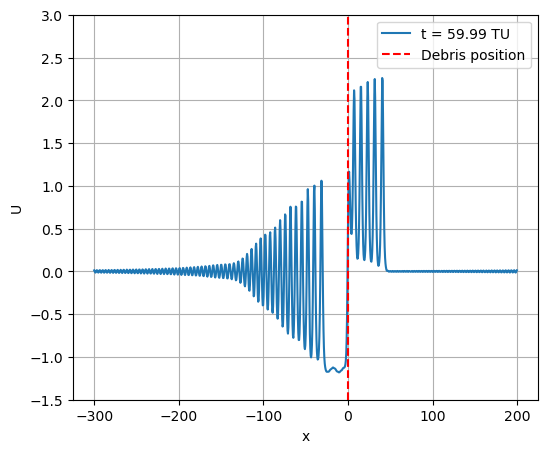

In [16]:
if __name__ == "__main__":

    xi = np.linspace(-L, L -100, N, endpoint=False)
    dxi = xi[1] - xi[0]

    # Defining mesh space & waven numbers
    s = 1
    k = 2*np.pi*np.fft.fftfreq(N, d=dxi)  # Defining mesh space & wave numbers

    np_potential = normalised_plasma_potential(a, plasma_prop["Debye Length"] * 1e-2, mass_ratio)

    time_steps = int(abs(tau_inital - tau_final)/dtau)

    sol = np.zeros(((time_steps) + 10,N)) # Intialisng with an exact solution
    sol[1] = 0 # SWITCH THIS TO START FROM RESTFRAME OR ANALYTICAL SOLITON

    time_array = np.zeros(time_steps+10)
    time_array[0] = tau_inital

    current_time = tau_inital + dtau   # first step is initalised by an exact solution, so we start the loop at the second time step
    current_step = 1

    while current_time < tau_final:
        time_array[current_step] = current_time

        f = forcing_term(np_potential, xi, current_time, vd_norm, G) # Calculating a forcing term for the debris

        if current_step < 5: # Helps stablise pertubations caused by starting from rest frame.
            current_dtau = dtau/10
        else:
            current_dtau = dtau

        next_sol = ck_solutions(last_sol = sol[current_step - 1], # Propogate exact solution forward in time with CK scheme
                           current_sol = sol[current_step],
                           alpha=alpha,
                           beta=beta,
                           s=s,
                           k=k,
                           f=f,
                           dt=current_dtau
                           )
        sol[current_step + 1] = next_sol

        if current_step % 1000 == 0:
            print(f"Time step: {current_step}, Time: {current_time:.2f} TU")
            print(f"Max value of solution: {np.max(sol[current_step + 1]):.4f}, Min value of solution: {np.min(sol[current_step + 1]):.4f}")

        current_time += current_dtau
        current_step += 1

    # ---Display the final solution at the last time step---
    for i in range(len(time_array)):
        if abs(time_array[i] - 60) < 1e-2:
            print(i)
            break
    print("Plotting.")

    plt.figure(figsize=(6,5))
    plt.plot(xi, sol[i], label=f"t = {time_array[i]:.2f} TU")
    plt.axvline(vd_norm * time_array[i] , color='red', linestyle='--', label="Debris position")
    plt.xlabel("x")
    plt.ylabel("U")
    plt.ylim(-1.5,3)
    plt.legend()
    plt.grid()
    plt.show()

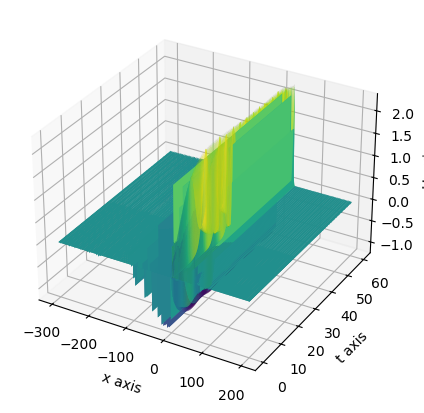

In [31]:
%matplotlib inline
import matplotlib.pyplot as plt

Xi, Tau = np.meshgrid(xi, time_array)  # Create meshgrid for plotting
fig = plt.figure(figsize=(6,5))
ax = plt.subplot(111, projection='3d')
surf = ax.plot_surface(Xi, Tau, sol, rstride=10, cstride=10, cmap='viridis', linewidth=1)

ax.set_xlabel('x axis')
ax.set_ylabel('t axis')
ax.set_zlabel('U axis')

plt.show()

In [18]:
print("Xi,Tau,sol:", Xi.shape, Tau.shape, sol.shape)
import numpy as np
print("finite?", np.all(np.isfinite(sol)))
print("min,max,nan/count:", np.nanmin(sol), np.nanmax(sol), np.count_nonzero(~np.isfinite(sol)))
print("example bad idx:", np.argwhere(~np.isfinite(sol))[:10])

# meshgrid(xi,time_array) -> Xi.shape == (len(time_array), len(xi))
if sol.shape != Xi.shape:
    sol = sol.T  # or sol.reshape(Xi.shape)

sol = np.real(sol)


mask = np.isfinite(sol)
sol_masked = np.where(mask, sol, np.nan)
fig = plt.figure(figsize=(6,5))
ax  = fig.add_subplot(111, projection='3d')
ax.plot_surface(Xi, Tau, sol_masked, cmap='viridis', linewidth=0, antialiased=True)
ax.set_zlim(np.percentile(sol[np.isfinite(sol)], [1,99]))  # clip extremes

Xi,Tau,sol: (30010, 1024) (30010, 1024) (30010, 1024)
finite? True
min,max,nan/count: -1.181549124387002 2.3043295901312257 0
example bad idx: []


(-1.1518318481529397, 1.5218393208416054)